## 1. 원본 로딩 및 구로구 정류소 추출

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "서울시버스정류소위치정보(20260902)"

def find_repo():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        candidate = p / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾을 수 없습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY

files = sorted(
    RAW_ROOT.rglob("서울시버스정류소위치정보(20260902)*.xlsx"),
    key=lambda p: (
        p.name != DATASET_KEY + ".xlsx",
        str(p)
    )
)

if not files:
    raise FileNotFoundError(
        f"원본 XLSX가 없습니다: {RAW_ROOT}"
    )

RAW_PATH = files[0]
raw = pd.read_excel(
    RAW_PATH,
    engine="openpyxl",
    dtype={"NODE_ID": "string", "ARS_ID": "string"}
)
raw.columns = raw.columns.astype(str).str.strip()

required = [
    "NODE_ID", "ARS_ID", "정류소명",
    "X좌표", "Y좌표", "정류소타입"
]
missing_cols = set(required) - set(raw.columns)
if missing_cols:
    raise ValueError(f"필수 컬럼이 없습니다: {missing_cols}")

# 단순히 저장된 행 번호를 반복하는 Unnamed 컬럼만 제거
for col in list(raw.columns):
    if col.startswith("Unnamed:"):
        values = pd.to_numeric(raw[col], errors="coerce")
        if values.notna().all() and np.array_equal(
            values.to_numpy(), np.arange(len(raw))
        ):
            raw.drop(columns=col, inplace=True)

def normalize_ars(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip()
    if re.fullmatch(r"\d+(\.0)?", value):
        value = value.split(".")[0].zfill(5)
    return value

raw["ARS_ID"] = (
    raw["ARS_ID"].map(normalize_ars).astype("string")
)
raw["NODE_ID"] = raw["NODE_ID"].astype("string").str.strip()
raw["정류소명"] = raw["정류소명"].astype("string").str.strip()
raw["정류소타입"] = raw["정류소타입"].astype("string").str.strip()

raw.reset_index(drop=True, inplace=True)
raw.insert(0, "source_row_id", np.arange(1, len(raw) + 1))

# 구로구 코드 기반 1차 추출
selected = raw.loc[
    raw["ARS_ID"].str.startswith("17", na=False)
].copy()

if selected.empty:
    raise ValueError(
        "ARS_ID 17로 시작하는 정류소가 없습니다. "
        "필터링 기준을 확인하세요."
    )

selected.reset_index(drop=True, inplace=True)

print("원본:", RAW_PATH.name)
print("pandas:", pd.__version__)
print("원본:", raw.shape)
print("구로구 코드 추출:", selected.shape)
print(
    "메모리(MB):",
    round(selected.memory_usage(deep=True).sum() / 1024**2, 3)
)
display(selected.head())
display(selected.dtypes.to_frame("dtype"))

원본: 서울시버스정류소위치정보(20260902).xlsx
pandas: 3.0.6
원본: (11236, 7)
구로구 코드 추출: (505, 7)
메모리(MB): 0.141


,source_row_id,NODE_ID,ARS_ID,정류소명,X좌표,Y좌표,정류소타입
0,6807,116000001,17001,신도림역,126.889223,37.509676,중앙차로
1,6808,116000002,17002,신도림역,126.888464,37.509108,중앙차로
2,6809,116000003,17003,신도림동.구로역,126.883979,37.506002,중앙차로
3,6810,116000004,17004,신도림동.구로역,126.883228,37.505344,중앙차로
4,6811,116000005,17005,구일역.중앙유통상가,126.874700,37.499881,중앙차로


,dtype
source_row_id,int64
NODE_ID,string
ARS_ID,string
정류소명,string
X좌표,float64
Y좌표,float64
정류소타입,string


## 2. 결측치 및 데이터 품질 분석

In [2]:
missing = pd.DataFrame({
    "missing_count": selected.isna().sum(),
    "missing_pct": selected.isna().mean() * 100
})
display(missing)

clean = selected.copy()
clean["X좌표"] = pd.to_numeric(clean["X좌표"], errors="coerce")
clean["Y좌표"] = pd.to_numeric(clean["Y좌표"], errors="coerce")

clean["coord_valid_broad"] = (
    clean["X좌표"].between(124, 132)
    & clean["Y좌표"].between(33, 39)
).fillna(False)

clean["duplicate_node_id_flag"] = (
    clean["NODE_ID"].duplicated(keep=False)
    & clean["NODE_ID"].notna()
)
clean["duplicate_ars_id_flag"] = (
    clean["ARS_ID"].duplicated(keep=False)
    & clean["ARS_ID"].notna()
)
clean["duplicate_coordinate_flag"] = (
    clean.duplicated(["X좌표", "Y좌표"], keep=False)
    & clean[["X좌표", "Y좌표"]].notna().all(axis=1)
)
clean["duplicate_name_flag"] = (
    clean["정류소명"].duplicated(keep=False)
    & clean["정류소명"].notna()
)

clean["guro_filter_method"] = "ARS_ID_prefix_17"

clean["review_needed"] = (
    ~clean["coord_valid_broad"]
    | clean["duplicate_node_id_flag"]
    | clean["duplicate_ars_id_flag"]
    | clean["duplicate_coordinate_flag"]
    | clean["NODE_ID"].isna()
    | clean["ARS_ID"].isna()
)

print("완전 중복:", int(selected.duplicated().sum()))
print("NODE_ID 중복:", int(clean["duplicate_node_id_flag"].sum()))
print("ARS_ID 중복:", int(clean["duplicate_ars_id_flag"].sum()))
print("좌표 중복:", int(clean["duplicate_coordinate_flag"].sum()))
print("이름 반복:", int(clean["duplicate_name_flag"].sum()))
print("좌표 오류:", int((~clean["coord_valid_broad"]).sum()))
print("검토 필요:", int(clean["review_needed"].sum()))

display(clean[["X좌표", "Y좌표"]].describe())
display(clean.loc[clean["review_needed"]].head(30))

,missing_count,missing_pct
source_row_id,0,0.0
NODE_ID,0,0.0
ARS_ID,0,0.0
정류소명,0,0.0
X좌표,0,0.0
Y좌표,0,0.0
정류소타입,0,0.0


완전 중복: 0
NODE_ID 중복: 0
ARS_ID 중복: 0
좌표 중복: 0
이름 반복: 283
좌표 오류: 0
검토 필요: 0


,X좌표,Y좌표
count,505.000000,505.000000
mean,126.861023,37.494109
std,0.023604,0.008702
min,126.816872,37.475893
25%,126.841990,37.487265
50%,126.857000,37.494265
75%,126.883688,37.500834
max,126.901828,37.514573


,source_row_id,NODE_ID,ARS_ID,정류소명,X좌표,Y좌표,정류소타입,coord_valid_broad,duplicate_node_id_flag,duplicate_ars_id_flag,duplicate_coordinate_flag,duplicate_name_flag,guro_filter_method,review_needed


## 3. 기초 통계 및 시각화

,record_count
정류소타입,
일반차로,247
마을버스,244
중앙차로,13
가로변전일,1


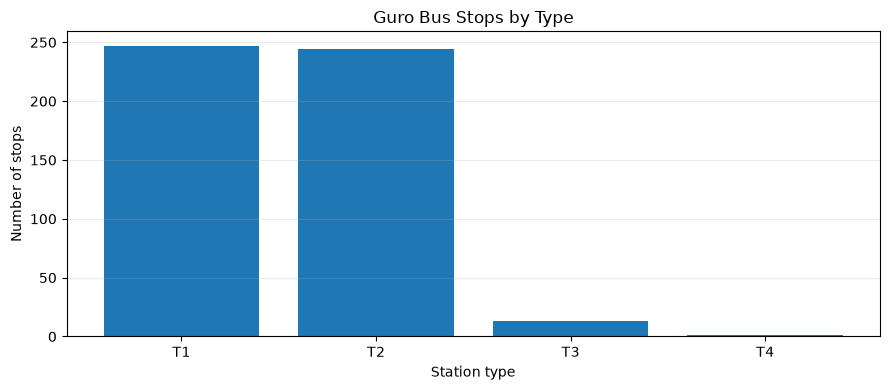

T1: 일반차로
T2: 마을버스
T3: 중앙차로
T4: 가로변전일


C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\asia\AppData\Local\Temp\ipykernel_31788\1411772186.py:32: UserWarning: Glyph 47560 (\N{HANGUL SYLLABLE MA}) missing from font(

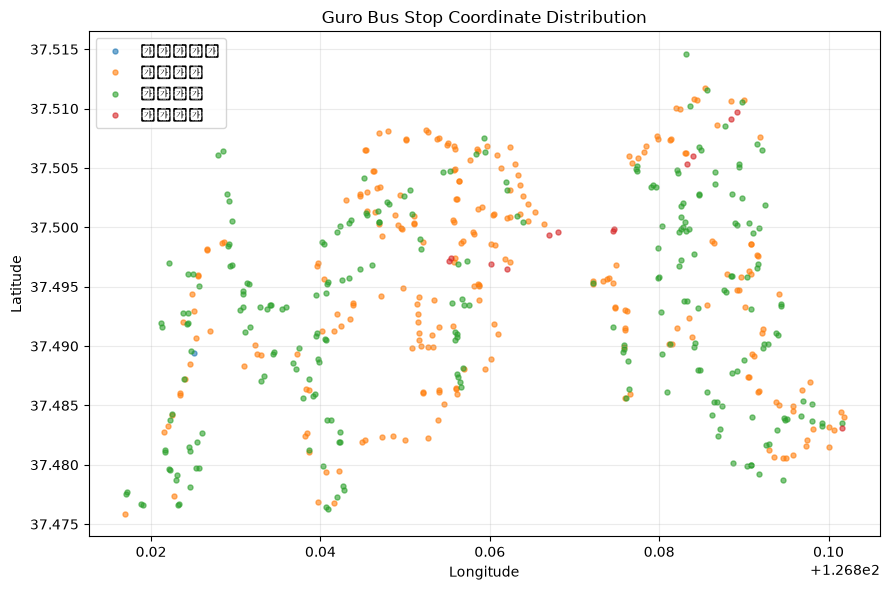

In [3]:
type_counts = clean["정류소타입"].value_counts(dropna=False)
display(type_counts.to_frame("record_count"))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(type_counts))
ax.bar(x, type_counts.values)
ax.set_xticks(x)
ax.set_xticklabels([f"T{i+1}" for i in x])
ax.set_title("Guro Bus Stops by Type")
ax.set_xlabel("Station type")
ax.set_ylabel("Number of stops")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for i, name in enumerate(type_counts.index, 1):
    print(f"T{i}: {name}")

valid = clean["coord_valid_broad"]

fig, ax = plt.subplots(figsize=(9, 6))
for name, group in clean.loc[valid].groupby("정류소타입"):
    ax.scatter(
        group["X좌표"], group["Y좌표"],
        s=13, alpha=0.6, label=name
    )
ax.set_title("Guro Bus Stop Coordinate Distribution")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. summary.csv 및 features.csv 생성

In [4]:
rows = []

def add(section, metric, category, value, unit=""):
    rows.append({
        "section": section,
        "metric": metric,
        "category": category,
        "value": value,
        "unit": unit
    })

overall = {
    "seoul_total_rows": len(raw),
    "guro_prefix_rows": len(selected),
    "unique_node_ids": clean["NODE_ID"].nunique(),
    "unique_ars_ids": clean["ARS_ID"].nunique(),
    "unique_coordinates": len(
        clean[["X좌표", "Y좌표"]].drop_duplicates()
    ),
    "unique_names": clean["정류소명"].nunique(),
    "duplicate_node_id_rows": int(
        clean["duplicate_node_id_flag"].sum()
    ),
    "duplicate_ars_id_rows": int(
        clean["duplicate_ars_id_flag"].sum()
    ),
    "duplicate_coordinate_rows": int(
        clean["duplicate_coordinate_flag"].sum()
    ),
    "duplicate_name_rows": int(
        clean["duplicate_name_flag"].sum()
    ),
    "invalid_coordinate_rows": int(
        (~clean["coord_valid_broad"]).sum()
    ),
    "review_needed_rows": int(clean["review_needed"].sum())
}

for metric, value in overall.items():
    add("overall", metric, "", value, "records")

add(
    "overall", "guro_prefix_ratio", "",
    100 * len(selected) / len(raw), "%"
)

for station_type, count in type_counts.items():
    add(
        "station_type", "record_count",
        str(station_type), count, "records"
    )

for col in selected.columns:
    add(
        "missing", "missing_count", col,
        selected[col].isna().sum(), "records"
    )
    add(
        "missing", "missing_pct", col,
        selected[col].isna().mean() * 100, "%"
    )

for col in ["X좌표", "Y좌표"]:
    for stat in ["min", "max", "mean", "median", "std"]:
        add(
            "numeric", stat, col,
            getattr(clean[col], stat)(), "degrees"
        )

summary = pd.DataFrame(rows)

features = clean[[
    "source_row_id", "NODE_ID", "ARS_ID",
    "X좌표", "Y좌표", "정류소타입",
    "coord_valid_broad", "review_needed"
]].rename(columns={
    "X좌표": "longitude",
    "Y좌표": "latitude",
    "정류소타입": "station_type"
})

features = pd.get_dummies(
    features,
    columns=["station_type"],
    dtype=int
)

print("clean:", clean.shape)
print("summary:", summary.shape)
print("features:", features.shape)
display(features.head())

clean: (505, 14)
summary: (41, 5)
features: (505, 11)


,source_row_id,NODE_ID,ARS_ID,longitude,latitude,coord_valid_broad,review_needed,station_type_가로변전일,station_type_마을버스,station_type_일반차로,station_type_중앙차로
0,6807,116000001,17001,126.889223,37.509676,True,False,0,0,0,1
1,6808,116000002,17002,126.888464,37.509108,True,False,0,0,0,1
2,6809,116000003,17003,126.883979,37.506002,True,False,0,0,0,1
3,6810,116000004,17004,126.883228,37.505344,True,False,0,0,0,1
4,6811,116000005,17005,126.874700,37.499881,True,False,0,0,0,1


## 5. CSV 저장 및 재읽기 검증

In [5]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "clean.csv": clean,
    "summary.csv": summary,
    "features.csv": features
}

loaded = {}

for name, df in outputs.items():
    path = OUT_DIR / name
    df.to_csv(path, index=False, encoding="utf-8-sig")

    dtype_map = (
        {"NODE_ID": "string", "ARS_ID": "string"}
        if name != "summary.csv" else None
    )
    reread = pd.read_csv(
        path, encoding="utf-8-sig", dtype=dtype_map
    )

    assert reread.shape == df.shape, name
    assert list(reread.columns) == list(df.columns), name
    assert path.read_bytes().startswith(b"\xef\xbb\xbf")
    loaded[name] = reread

assert (
    loaded["clean.csv"]["source_row_id"].tolist()
    == clean["source_row_id"].tolist()
)
assert (
    loaded["features.csv"]["source_row_id"].tolist()
    == features["source_row_id"].tolist()
)

for col in ["X좌표", "Y좌표"]:
    assert np.allclose(
        loaded["clean.csv"][col].to_numpy(dtype=float),
        clean[col].to_numpy(dtype=float),
        equal_nan=True, atol=1e-9, rtol=0
    )

for col in ["ARS_ID", "NODE_ID"]:
    assert (
        loaded["clean.csv"][col].fillna("").tolist()
        == clean[col].fillna("").tolist()
    )

print("CSV 저장 및 검증 완료")

CSV 저장 및 검증 완료


## 6. README.md 생성 및 검증

In [6]:
descriptions = {
    "source_row_id": "원본 데이터 행 순서에 따라 생성한 식별자",
    "NODE_ID": "서울시 버스정류소 노드 식별자",
    "ARS_ID": "정류소 안내번호. 앞자리 0 보존",
    "정류소명": "버스정류소 이름",
    "X좌표": "경도",
    "Y좌표": "위도",
    "정류소타입": "정류소 유형",
    "coord_valid_broad": "광범위 좌표 범위 검증 결과",
    "duplicate_node_id_flag": "NODE_ID 반복 여부",
    "duplicate_ars_id_flag": "ARS_ID 반복 여부",
    "duplicate_coordinate_flag": "동일 좌표 반복 여부",
    "duplicate_name_flag": "동일 정류소명 반복 여부",
    "guro_filter_method": "구로구 1차 추출 기준",
    "review_needed": "데이터 검토 필요 여부",
    "section": "통계 그룹",
    "metric": "통계 지표",
    "category": "집계 대상",
    "value": "계산된 통계값",
    "unit": "통계값 단위",
    "longitude": "원본 X좌표로부터 생성한 경도",
    "latitude": "원본 Y좌표로부터 생성한 위도"
}

def describe(col):
    if col.startswith("station_type_"):
        return "해당 정류소 유형이면 1, 아니면 0: " + (
            col.removeprefix("station_type_")
        )
    return descriptions.get(col, "원본 컬럼 설명 확인 필요")

def escape_md(value):
    return str(value).replace("|", "\\|").replace("\n", " ")

lines = [
    "# 서울시 버스정류소 위치정보 — CSV 사용 설명서",
    "",
    f"- 원본: `{RAW_PATH.name}`",
    "- 데이터 기준일: 2026-09-02 (파일명 기준)",
    "- 분석 대상: 구로구 코드 기반 정류소",
    "- 추출 조건: `ARS_ID`가 `17`로 시작",
    "- 행정경계 공간 검증: 미실시",
    f"- 서울 원본: {len(raw):,}행",
    f"- 구로구 코드 추출: {len(clean):,}행",
    "",
    "## 전처리",
    "",
    "- 정류소 식별자를 문자열로 보존",
    "- 숫자형 ARS_ID는 5자리로 정규화",
    "- 원본 행 식별자 생성",
    "- 위도·경도 수치형 변환",
    "- 좌표·식별자 중복 및 품질 플래그 생성",
    "- 중복 정류소명은 삭제하지 않음",
    "",
    "## CSV별 컬럼 설명",
    ""
]

purposes = {
    "clean.csv": "구로구 코드 기반 정류소 정제 데이터",
    "summary.csv": "기초 통계 및 품질 분석 결과",
    "features.csv": "공간 분석 및 머신러닝 입력 변수 후보"
}

for filename, frame in loaded.items():
    lines += [
        f"### {filename}",
        "",
        f"**목적:** {purposes[filename]}",
        "",
        f"**크기:** {len(frame)}행 × {len(frame.columns)}열",
        "",
        "| 컬럼명 | 자료형 | 의미 |",
        "|---|---|---|"
    ]
    for col in frame.columns:
        lines.append(
            f"| `{escape_md(col)}` | `{frame[col].dtype}` "
            f"| {escape_md(describe(col))} |"
        )
    lines.append("")

lines += [
    "## summary.csv 집계 기준",
    "",
    "- `overall`: 전체 규모와 품질 통계",
    "- `station_type`: 정류소 유형별 등록 건수",
    "- `missing`: 컬럼별 결측 건수 및 비율",
    "- `numeric`: 위도·경도 기술통계",
    "",
    "## CSV 간 관계",
    "",
    "- `clean.csv`와 `features.csv`는 정류소 행 단위",
    "- 두 파일은 `source_row_id`로 연결",
    "- `summary.csv`는 집계 결과로 행 단위가 다름",
    "- `NODE_ID`, `ARS_ID`는 식별자이며 모델의 "
    "연속형 수치 변수로 직접 취급하지 않음",
    "",
    "## 사용 시 주의사항",
    "",
    "- ARS_ID 17 접두어는 구로구 1차 분류 기준",
    "- 실제 구로구 행정경계와의 공간 검증은 필요",
    "- 동일 정류소명은 방향별 정류소일 수 있음",
    "- 좌표는 경도·위도 형태이며 거리 계산 시 투영 필요",
    "- 정류소 위치는 실제 흡연 발생의 정답이 아님",
    "- 250m 격자와 도보 네트워크는 아직 미결합",
    "- 시간대별 흡연 관측 자료 없음",
    ""
]

readme_path = OUT_DIR / "README.md"
readme_path.write_text(
    "\n".join(lines), encoding="utf-8"
)

readme_text = readme_path.read_text(encoding="utf-8")
for frame in loaded.values():
    for col in frame.columns:
        assert f"`{col}`" in readme_text

print("README.md 생성 및 검증 완료")
for path in sorted(OUT_DIR.iterdir()):
    print(path.name, path.stat().st_size, "bytes")

README.md 생성 및 검증 완료
clean.csv 70005 bytes
features.csv 35158 bytes
README.md 4158 bytes
summary.csv 1860 bytes
